In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("/content/spam.csv", encoding='latin-1')

In [4]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [5]:
df.shape

(5572, 5)

In [6]:
df.isnull().sum()

,0
v1,0
v2,0
Unnamed: 2,5522
Unnamed: 3,5560
Unnamed: 4,5566


In [7]:
df=df.drop(columns=["Unnamed: 2","Unnamed: 3","Unnamed: 4"],axis=1)

In [8]:
df.isnull().sum()

,0
v1,0
v2,0


In [9]:
df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [10]:
df = df.rename(columns={"v1": "label", "v2": "message"})

In [11]:
df["label"].value_counts()

,count
label,
ham,4825
spam,747


Here, we can see that the class distribution is: ham-4825
                                                 spam-747

In [12]:
total=df["label"].value_counts().sum()
total

np.int64(5572)

In [13]:
df["label"].value_counts()/total*100

,count
label,
ham,86.593683
spam,13.406317


We see 86.59% ham and only 13.40% spam

In [14]:
df = df.rename(columns={"v1": "label", "v2": "message"})

In [15]:
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [16]:
df.shape

(5572, 2)

In [17]:
df.head(100)

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
95,spam,Your free ringtone is waiting to be collected....
96,ham,Watching telugu movie..wat abt u?
97,ham,i see. When we finish we have loads of loans t...
98,ham,Hi. Wk been ok - on hols now! Yes on for a bit...


In [18]:
df.duplicated().sum()

np.int64(403)

In [19]:
df=df.drop_duplicates(keep="first")

Here we found out that the number of duplicated values are 403, we wouldn't want the model to train the repeated values

In [20]:
df.shape

(5169, 2)

In [21]:
df["message"].str.len().head(10)

,message
0,111
1,29
2,155
3,49
4,61
5,148
6,77
7,160
8,158
9,154


In [22]:
import re

In [23]:
import nltk

nltk.download('stopwords')
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [24]:
text = "this is a free prize"

words = text.split()

In [25]:
words

['this', 'is', 'a', 'free', 'prize']

In [26]:
" ".join([w for w in words if w not in stop_words])

'free prize'

In [27]:
stop_words.discard("not")
stop_words.discard("no")

In [28]:
def preprocess_text(text):
    # Convert text to lowercase
    text=text.lower()
    text=re.sub(r'[^a-zA-Z0-9\s]','',text)
    words=text.split()
    text=" ".join([w for w in words if w not in stop_words])
    return text

In [29]:
preprocess_text("we've got a FREE Prize NOW!")

'weve got free prize'

In [30]:
df["Clean Message"]=df["message"].apply(preprocess_text)

In [31]:
df["Clean Message"]

,Clean Message
0,go jurong point crazy available bugis n great ...
1,ok lar joking wif u oni
2,free entry 2 wkly comp win fa cup final tkts 2...
3,u dun say early hor u c already say
4,nah dont think goes usf lives around though
...,...
5567,2nd time tried 2 contact u u 750 pound prize 2...
5568,b going esplanade fr home
5569,pity mood soany suggestions
5570,guy bitching acted like id interested buying s...


In [32]:
df[["message", "Clean Message"]].head(10)

,message,Clean Message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry 2 wkly comp win fa cup final tkts 2...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling 3 weeks no word back id li...
6,Even my brother is not like to speak with me. ...,even brother not like speak treat like aids pa...
7,As per your request 'Melle Melle (Oru Minnamin...,per request melle melle oru minnaminunginte nu...
8,WINNER!! As a valued network customer you have...,winner valued network customer selected receiv...
9,Had your mobile 11 months or more? U R entitle...,mobile 11 months u r entitled update latest co...


In [33]:
(df["Clean Message"].str.strip() == "").sum()

np.int64(3)

In [34]:
df.shape

(5169, 3)

In [35]:
from sklearn.model_selection import train_test_split

X=df[["message","Clean Message"]]
y=df["label"].map({"ham":0,"spam":1})

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [36]:
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining label distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting label distribution:")
print(y_test.value_counts(normalize=True))

Training shape: (4135, 2)
Testing shape: (1034, 2)

Training label distribution:
label
0    0.873761
1    0.126239
Name: proportion, dtype: float64

Testing label distribution:
label
0    0.873308
1    0.126692
Name: proportion, dtype: float64


In [37]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train["Clean Message"])
X_test_tfidf = tfidf.transform(X_test["Clean Message"])

In [38]:
X_test_tfidf[0]

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 16 stored elements and shape (1, 8046)>

Multinomial Naive Bayes

In [45]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

MultinomialNB()

In [46]:
y_pred = nb_model.predict(X_test_tfidf)

In [48]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.960348162475822
Precision: 0.9891304347826086
Recall: 0.6946564885496184
F1 Score: 0.8161434977578476

Confusion Matrix:
[[902   1]
 [ 40  91]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       903
           1       0.99      0.69      0.82       131

    accuracy                           0.96      1034
   macro avg       0.97      0.85      0.90      1034
weighted avg       0.96      0.96      0.96      1034



SVM

TF-IDF currently represents each message using 8,046 features. We need to reduce those dimensions to just two.

We'll use a technique called Truncated Singular Value Decomposition (SVD)

In [58]:
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train["Clean Message"],
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [59]:
print("Training:", X_subtrain.shape)
print("Validation:", X_val.shape)
print("Training distribution:")
print(y_subtrain.value_counts(normalize=True))

print("Validation distribution:")
print(y_val.value_counts(normalize=True))

Training: (3308,)
Validation: (827,)
Training distribution:
label
0    0.87364
1    0.12636
Name: proportion, dtype: float64
Validation distribution:
label
0    0.874244
1    0.125756
Name: proportion, dtype: float64


In [60]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

X_subtrain_tfidf = tfidf.fit_transform(X_subtrain)
X_val_tfidf = tfidf.transform(X_val)

In [61]:
print("Training:", X_subtrain_tfidf.shape)
print("Validation:", X_val_tfidf.shape)

Training: (3308, 6963)
Validation: (827, 6963)


svd

In [67]:
from sklearn.decomposition import TruncatedSVD
n_comp=[50, 100, 200, 300, 500]
var_vals_list=[]
for i in n_comp:
  svd = TruncatedSVD(n_components=i, random_state=42)
  X_subtrain_svd = svd.fit_transform(X_subtrain_tfidf)
  X_val_svd = svd.transform(X_val_tfidf)
  var=svd.explained_variance_ratio_.sum() * 100
  var_vals_list.append(var)
  print(f"Number of components: {i}")
  print(f"Variance retained: {var:.2f}%")
  print("Training:", X_subtrain_svd.shape)
  print("Validation:", X_val_svd.shape)

Number of components: 50
Variance retained: 15.60%
Training: (3308, 50)
Validation: (827, 50)
Number of components: 100
Variance retained: 24.38%
Training: (3308, 100)
Validation: (827, 100)
Number of components: 200
Variance retained: 36.15%
Training: (3308, 200)
Validation: (827, 200)
Number of components: 300
Variance retained: 44.60%
Training: (3308, 300)
Validation: (827, 300)
Number of components: 500
Variance retained: 56.66%
Training: (3308, 500)
Validation: (827, 500)


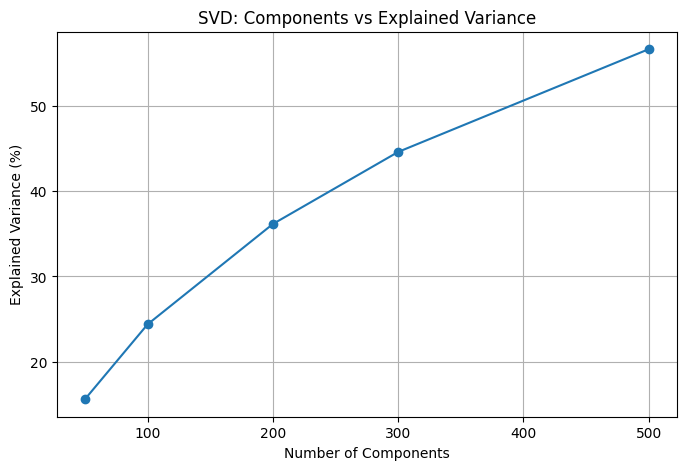

In [69]:
plt.figure(figsize=(8, 5))

plt.plot(n_comp, var_vals_list, marker='o')

plt.xlabel("Number of Components")
plt.ylabel("Explained Variance (%)")
plt.title("SVD: Components vs Explained Variance")

plt.grid()
plt.show()

In [70]:
svd_results = {}

for i in n_comp:
    svd = TruncatedSVD(n_components=i, random_state=42)

    X_train_reduced = svd.fit_transform(X_subtrain_tfidf)
    X_val_reduced = svd.transform(X_val_tfidf)

    svd_results[i] = (X_train_reduced, X_val_reduced)

In [71]:
svd_results

{50: (array([[ 0.08875655, -0.08618376,  0.25927862, ...,  0.01691751,
          -0.02566343, -0.00285942],
         [ 0.06903958, -0.01721735, -0.00497769, ..., -0.01164646,
          -0.00625885, -0.00164081],
         [ 0.0760749 , -0.06618596,  0.17842227, ..., -0.04795243,
          -0.02642959,  0.00859694],
         ...,
         [ 0.02772665, -0.01723054, -0.01302085, ...,  0.01033712,
          -0.02553587,  0.01298145],
         [ 0.11703077, -0.06591077, -0.05788605, ..., -0.07908616,
          -0.00052313, -0.00428535],
         [ 0.0770839 , -0.03748256,  0.04189552, ..., -0.00540423,
          -0.03613413,  0.05246545]], shape=(3308, 50)),
  array([[ 0.04737524, -0.01480402, -0.01521263, ..., -0.03920959,
          -0.02452611, -0.00700038],
         [ 0.06069907, -0.04858512,  0.0394789 , ..., -0.02200338,
          -0.01928609, -0.02484596],
         [ 0.22322278, -0.09886364, -0.15471219, ...,  0.01163813,
          -0.01151341,  0.04430554],
         ...,
         [ 0

My input data was represented using TF-IDF, which resulted in a high-dimensional sparse matrix. I selected Truncated SVD because it works directly with sparse matrices without requiring centering, unlike conventional PCA. It allowed me to reduce the feature space while retaining important latent patterns in the text data. I also experimented with different component counts and evaluated their impact on classification performance rather than selecting a dimension solely based on explained variance.

In [74]:
from sklearn.svm import SVC

kernel = ["linear", "poly", "rbf"]
c = [1, 10, 50, 100, 200, 500, 1000]
comp = [50, 100, 200, 300, 500]

results = []

for n in comp:

    # Get the SVD data for the current component count
    X_subtrain_svd = svd_results[n][0]
    X_val_svd = svd_results[n][1]

    for k in kernel:
        for v in c:

            svm_model = SVC(
                kernel=k,
                C=v,
                class_weight="balanced"
            )

            svm_model.fit(X_subtrain_svd, y_subtrain)

            y_pred = svm_model.predict(X_val_svd)

            results.append({
                "Components": n,
                "Kernel": k,
                "C": v,
                "Accuracy": accuracy_score(y_val, y_pred),
                "Precision": precision_score(y_val, y_pred),
                "Recall": recall_score(y_val, y_pred),
                "F1 Score": f1_score(y_val, y_pred)
            })

            print("Components:", n)
            print("Kernel:", k)
            print("C:", v)
            print("Accuracy:", accuracy_score(y_val, y_pred))
            print("Precision:", precision_score(y_val, y_pred))
            print("Recall:", recall_score(y_val, y_pred))
            print("F1 Score:", f1_score(y_val, y_pred))
            print("-" * 40)

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

results_df

Components: 50
Kernel: linear
C: 1
Accuracy: 0.939540507859734
Precision: 0.7327586206896551
Recall: 0.8173076923076923
F1 Score: 0.7727272727272727
----------------------------------------
Components: 50
Kernel: linear
C: 10
Accuracy: 0.932285368802902
Precision: 0.6935483870967742
Recall: 0.8269230769230769
F1 Score: 0.7543859649122807
----------------------------------------
Components: 50
Kernel: linear
C: 50
Accuracy: 0.9347037484885127
Precision: 0.7049180327868853
Recall: 0.8269230769230769
F1 Score: 0.7610619469026548
----------------------------------------
Components: 50
Kernel: linear
C: 100
Accuracy: 0.9347037484885127
Precision: 0.7049180327868853
Recall: 0.8269230769230769
F1 Score: 0.7610619469026548
----------------------------------------
Components: 50
Kernel: linear
C: 200
Accuracy: 0.9359129383313181
Precision: 0.7107438016528925
Recall: 0.8269230769230769
F1 Score: 0.7644444444444445
----------------------------------------
Components: 50
Kernel: linear
C: 500
Accu

,Components,Kernel,C,Accuracy,Precision,Recall,F1 Score
0,500,rbf,1,0.969770,0.907216,0.846154,0.875622
1,500,rbf,10,0.969770,0.915789,0.836538,0.874372
2,500,rbf,100,0.969770,0.915789,0.836538,0.874372
3,500,rbf,50,0.969770,0.915789,0.836538,0.874372
4,500,rbf,1000,0.969770,0.915789,0.836538,0.874372
...,...,...,...,...,...,...,...
100,500,poly,50,0.932285,0.852941,0.557692,0.674419
101,500,poly,100,0.927449,0.805556,0.557692,0.659091
102,500,poly,500,0.927449,0.805556,0.557692,0.659091
103,500,poly,1000,0.927449,0.805556,0.557692,0.659091


In [75]:
results_df.groupby("Components")[["Accuracy", "Precision", "Recall", "F1 Score"]].max()

,Accuracy,Precision,Recall,F1 Score
Components,,,,
50,0.960097,0.901235,0.865385,0.842105
100,0.957678,0.900000,0.846154,0.832536
200,0.964933,0.902778,0.836538,0.854271
300,0.968561,0.924242,0.846154,0.871287
500,0.969770,0.933333,0.846154,0.875622


In [76]:
X_train_tfidf.shape

(4135, 8046)

In [78]:
from sklearn.decomposition import TruncatedSVD
svd_final = TruncatedSVD(n_components=500, random_state=42)
X_train_svd_final = svd_final.fit_transform(X_train_tfidf)
X_test_svd_final = svd_final.transform(X_test_tfidf)
print(X_train_svd_final.shape)
print(X_test_svd_final.shape)

(4135, 500)
(1034, 500)


In [79]:
svm_final = SVC(
    kernel="rbf",
    C=1,
    class_weight="balanced"
)

svm_final.fit(X_train_svd_final, y_train)

SVC(C=1, class_weight='balanced')

In [80]:
svm_predictions = svm_final.predict(X_test_svd_final)

In [81]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, svm_predictions))
print("Precision:", precision_score(y_test, svm_predictions))
print("Recall:", recall_score(y_test, svm_predictions))
print("F1 Score:", f1_score(y_test, svm_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_predictions))

print("\nClassification Report:")
print(classification_report(y_test, svm_predictions))

Accuracy: 0.9816247582205029
Precision: 0.9444444444444444
Recall: 0.9083969465648855
F1 Score: 0.9260700389105059

Confusion Matrix:
[[896   7]
 [ 12 119]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       903
           1       0.94      0.91      0.93       131

    accuracy                           0.98      1034
   macro avg       0.97      0.95      0.96      1034
weighted avg       0.98      0.98      0.98      1034

